# 4. Model Selection and Training

This notebook develops and evaluates regression models for predicting actual production quantity (`actual_qty`) in the DI Leather shoe manufacturing division.

The workflow includes loading the engineered dataset, creating a chronological train–test split, building a preprocessing pipeline, tuning seven candidate regression models with time-series cross-validation, comparing their results, selecting the model with the lowest cross-validation MAE, analysing residuals and permutation feature importance, and saving the selected pipeline for Notebook 5.

The dataset contains **9,495 records and 18 columns**. The training set contains **7,596 records** from **18 April 2022 to 24 March 2025**, while the test set contains **1,899 records** from **24 March 2025 to 30 March 2026**.

**Current results.** **XGBoost** is selected because it has the lowest cross-validation MAE (**4.875**). On the chronological test set it achieves R² **0.795**, MAE **4.507**, and RMSE **5.920**. Gradient Boosting is a close second (cross-validation MAE **4.897**; test R² **0.790**, MAE **4.566**, RMSE **5.991**). Because the selection uses cross-validation results from the training period only, the test period remains an independent final evaluation.


# 4.1 Part A – Hyperparameter Tuning and Model Selection

Seven regression algorithms are compared: Linear Regression, Ridge Regression, Lasso Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost. Linear Regression serves as the baseline model.

Hyperparameter tuning is performed before the final model is selected. The tunable models use `RandomizedSearchCV` with five-fold `TimeSeriesSplit` cross-validation and negative MAE scoring. Linear Regression has no meaningful hyperparameter search in this notebook and is evaluated across the five validation folds.

The selection code ranks the tuned models by **cross-validation MAE** (lowest first). This criterion uses only training-period records, so the held-out test period is not used to choose the model. Test metrics are calculated for every model and reported to assess performance on the later period.


### 4.1.1 Import Libraries and Required Functions

The required libraries are imported for data manipulation, preprocessing, regression modelling, hyperparameter tuning, performance evaluation, diagnostics, and model saving.

Scikit-learn provides the regression algorithms, preprocessing transformers, pipelines, search tools, and evaluation metrics. XGBoost provides an additional gradient-boosting implementation, while Joblib is used to save and reload the final model.

The tuning components are:

- `TimeSeriesSplit`: Creates cross-validation folds that always train on earlier records and validate on later records.
- `RandomizedSearchCV`: Evaluates a fixed number of randomly sampled hyperparameter combinations using cross-validation.
- `cross_val_score`: Provides a cross-validated score for a model that has no hyperparameters to tune.

The evaluation functions include:

- `r2_score`: Measures how well the predictions explain variation in the target.
- `mean_absolute_error`: Calculates the average absolute prediction error.
- `mean_squared_error`: Calculates the mean squared prediction error, from which RMSE is obtained.

The `Pipeline` and `ColumnTransformer` components allow preprocessing and modelling to be managed as one workflow. This ensures that transformations are fitted on the training data (and, during tuning, on each training fold) rather than independently using information from validation or test data.

In [1]:
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from pathlib import Path
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV,
    cross_val_score
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

warnings.filterwarnings("default", category=FutureWarning)



### 4.1.2 Load the Feature Dataset

The engineered feature dataset is loaded from `final_features.csv`, and `week_start_date` is parsed as a datetime column.

The dataset contains 9,495 records and 18 columns, including the target variable, the date used to preserve chronological order, and the prepared predictors.

An assertion checks that `week_start_date` is in ascending chronological order. If the records are not correctly ordered, the notebook stops instead of proceeding with an invalid time-based split.

This validation is important because the project forecasts production quantities over time. Training on randomly mixed records could allow observations from later periods to influence a model evaluated on earlier periods, resulting in an unrealistic assessment of forecasting performance.

The date column is retained for ordering and split verification, but it is excluded from the predictors in the model training step.

In [2]:

# Load the final feature dataset

input_path = Path("../data/processed/final_features.csv")

if not input_path.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {input_path.resolve()}\n"
        "Run Notebook 3 first and confirm that final_features.csv "
        "was saved in data/processed/."
    )

df = pd.read_csv(
    input_path,
    parse_dates=["week_start_date"]
)

# Validate required columns
required_cols = [
    "week_start_date",
    "actual_qty",
    "financial_month",
    "factory_unit",
    "product_family",
    "item_name",
    "size_id",
    "grade",
    "rate",
    "no_of_workers",
    "working_hours",
    "machine_count",
    "order_category",
    "bottleneck_flag",
    "machine_worker_ratio",
    "avg_hours_per_worker"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(
        f"Required columns are missing from the feature dataset: {missing_cols}"
    )

if df["week_start_date"].isna().any():
    raise ValueError("Missing dates found in week_start_date.")

if df["actual_qty"].isna().any():
    raise ValueError("Missing target values found in actual_qty.")

# Ensure chronological ordering
df = df.sort_values("week_start_date").reset_index(drop=True)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Date range:", df["week_start_date"].min(), "to", df["week_start_date"].max())
print("Target variable: actual_qty")

display(df.head())


Dataset loaded successfully.
Dataset shape: (9495, 18)
Date range: 2022-04-18 00:00:00 to 2026-03-30 00:00:00
Target variable: actual_qty


,week_start_date,financial_month,week_no,week_of_month,factory_unit,product_family,item_name,size_id,grade,rate,no_of_workers,working_hours,machine_count,bottleneck_flag,order_category,machine_worker_ratio,avg_hours_per_worker,actual_qty
0,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,4363.35,15,647.82,5,1,Others,0.333333,43.188000,38
1,2022-04-18,Apr,3,3,Factory Unit 01,Gents,JORDY - L - BLACK,11,B,2982.20,27,1134.10,6,0,Others,0.222222,42.003704,58
2,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,7003.71,15,673.07,3,0,Others,0.200000,44.871333,44
3,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,4676.91,11,550.89,3,0,Forces/Police,0.272727,50.080909,31
4,2022-04-18,Apr,3,3,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,3803.13,18,813.02,5,1,Forces/Police,0.277778,45.167778,36


### 4.1.3 Define the Target, Predictors, and Chronological Split

The target variable is `actual_qty`, representing the actual quantity produced for each record.

The predictors are the remaining columns after excluding `actual_qty` and `week_start_date`. The date column is excluded from the model inputs because it is used to preserve the chronological sequence rather than as a direct predictor.

The dataset is divided into two parts:

- **Training set:** The first 80% of the chronologically ordered records.
- **Testing set:** The most recent 20% of the records.

The training set contains 7,596 records, covering 18 April 2022 to 24 March 2025. The test set contains 1,899 records, covering 24 March 2025 to 30 March 2026.

A chronological split is appropriate because the intended application is forecasting future production. The model learns from earlier production records and is evaluated on a later period that it did not use for fitting.

No random shuffling is performed. This preserves the time direction of the prediction problem and gives a more realistic estimate of how the models may perform on later production observations.

The test set is reserved for the final evaluation of the tuned models. It is not used to fit preprocessing transformations, to fit model parameters, to choose hyperparameters, or to select the final model. Hyperparameter tuning and model selection are carried out using cross-validation within the training set only.

In [3]:

# Define target and predictors

target = "actual_qty"
date_column = "week_start_date"

# Exclude the target and date key from the model inputs
X_full = df.drop(columns=[target, date_column])
y_full = df[target]

# Chronological 80/20 train-test split
split_idx = int(len(df) * 0.80)

X_train = X_full.iloc[:split_idx].copy()
X_test = X_full.iloc[split_idx:].copy()

y_train = y_full.iloc[:split_idx].copy()
y_test = y_full.iloc[split_idx:].copy()

# Validate the split
assert len(X_train) + len(X_test) == len(df)
assert len(X_test) > 0
assert X_train.index.max() < X_test.index.min()

print(f"Total records: {len(df):,}")
print(
    f"Training records: {len(X_train):,} "
    f"({df['week_start_date'].iloc[0].date()} to "
    f"{df['week_start_date'].iloc[split_idx - 1].date()})"
)
print(
    f"Testing records: {len(X_test):,} "
    f"({df['week_start_date'].iloc[split_idx].date()} to "
    f"{df['week_start_date'].iloc[-1].date()})"
)
print(f"Number of model input features: {X_full.shape[1]}")
print(f"Target: {target}")


Total records: 9,495
Training records: 7,596 (2022-04-18 to 2025-03-24)
Testing records: 1,899 (2025-03-24 to 2026-03-30)
Number of model input features: 16
Target: actual_qty


### 4.1.4 Why a Chronological Split Is Necessary

In a forecasting problem, the order of observations matters because future production records would not be available when predictions are made for an earlier period.

A random train–test split can mix earlier and later observations. This may allow a model to learn patterns from periods that occur after some of the records it is evaluated on, making the evaluation less representative of actual forecasting.

The chronological split avoids this problem by using earlier records for training and later records for testing.

The test results therefore indicate how well each model generalises to a later period under the current evaluation setup. They do not guarantee identical performance in every future period, particularly if production processes or operating conditions change.

The training and testing periods should remain unchanged while comparing the seven candidate models so that the results are directly comparable.


### 4.1.5 Feature Scaling and Preprocessing

Feature scaling is performed using `StandardScaler` inside the modelling pipeline. Each numerical predictor is standardized using the mean and standard deviation learned from the training data.

The standardization formula is:

$$
z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

where:

- \(x\) is the original numerical feature value.
- \(\mu_{\text{train}}\) is the mean calculated from the training data.
- \(\sigma_{\text{train}}\) is the standard deviation calculated from the training data.
- \(z\) is the standardized feature value.

Standardization places numerical features on a comparable scale. It is particularly useful for Linear Regression, Ridge Regression, and Lasso Regression because differences in feature scales can affect regularization and model behaviour.

Tree-based models generally do not require feature scaling. However, the same preprocessing framework is used consistently when comparing the candidate models.

The scaler is fitted within each model pipeline using the training data, preventing information from the held-out test set from influencing the scaling parameters.

Categorical features are encoded separately using the appropriate encoding methods, while `bottleneck_flag` retains its existing binary representation.


### 4.1.6 Build the Preprocessing Pipeline

The dataset contains numerical, binary, and categorical variables. These variable types require different preprocessing methods before being supplied to the regression models.

The preprocessing operations are placed inside a `ColumnTransformer`, which is then included in a modelling pipeline.

The transformations are:

| Transformer | Variables | Purpose |
|---|---|---|
| `StandardScaler` | Numerical features | Standardises each feature using the training data's mean and standard deviation. |
| `OneHotEncoder` | `financial_month`, `factory_unit`, `product_family`, `grade`, `order_category`, `size_id` | Converts categories into binary indicator columns. |
| `TargetEncoder` | `item_name` | Represents each item using a smoothed target-based encoding. |
| `passthrough` | `bottleneck_flag` | Retains the existing 0/1 representation. |

**Why use a pipeline?**

The preprocessing transformations are fitted as part of the model pipeline. When the pipeline is trained, the transformations learn from the training data rather than from the complete dataset.

This is important for preventing information leakage. For example, the scaler should not use the test set's mean and standard deviation, and target encoding should not use the held-out test targets to determine item encodings.

One-hot encoding uses `handle_unknown='ignore'`, allowing the pipeline to handle categories that were not observed during training without failing. For target encoding, unseen items can be represented using the encoder's overall target-based fallback.

Using the same preprocessing design for all candidate models makes the comparison more consistent and ensures that the final saved model contains both the required transformations and the selected regression algorithm.

In [4]:

# Define feature groups

categorical_ohe = [
    "financial_month",
    "factory_unit",
    "product_family",
    "grade",
    "order_category",
    "size_id"
]

categorical_target = ["item_name"]
binary_cols = ["bottleneck_flag"]

expected_features = categorical_ohe + categorical_target + binary_cols

missing_features = [
    col for col in expected_features
    if col not in X_train.columns
]

if missing_features:
    raise ValueError(
        f"Expected features are missing: {missing_features}"
    )

# All remaining model inputs are numerical features
numerical_cols = [
    col for col in X_train.columns
    if col not in expected_features
]

if not numerical_cols:
    raise ValueError("No numerical features were identified.")

# Check numerical input values
if not np.isfinite(X_train[numerical_cols].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite values found in numerical training features.")

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        (
            "cat_ohe",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_ohe
        ),
        (
            "cat_te",
            TargetEncoder(target_type="continuous"),
            categorical_target
        ),
        ("binary", "passthrough", binary_cols)
    ]
)

print("Numerical features:", numerical_cols)
print("One-hot encoded features:", categorical_ohe)
print("Target-encoded features:", categorical_target)
print("Binary features:", binary_cols)
print("Total input columns:", X_train.shape[1])


Numerical features: ['week_no', 'week_of_month', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'machine_worker_ratio', 'avg_hours_per_worker']
One-hot encoded features: ['financial_month', 'factory_unit', 'product_family', 'grade', 'order_category', 'size_id']
Target-encoded features: ['item_name']
Binary features: ['bottleneck_flag']
Total input columns: 16


### 4.1.7 Candidate Regression Models

Seven regression models are evaluated to compare different approaches to predicting actual production quantity.

The models cover three main families:

| Model family | Candidate models | Main purpose |
|---|---|---|
| Linear models | Linear Regression, Ridge Regression, Lasso Regression | Establish a simple relationship between predictors and the target, with regularisation options. |
| Bagged tree models | Random Forest, Extra Trees | Capture nonlinear relationships and interactions using collections of decision trees. |
| Boosted tree models | Gradient Boosting, XGBoost | Build an ensemble sequentially, improving predictions by learning from earlier errors. |

Including different model families is useful because the relationships between workforce, machine availability, operating conditions, and production quantity may not be entirely linear.

Linear models provide interpretable reference points, while tree-based models can learn more complex relationships. Comparing them helps establish whether additional model complexity improves prediction on the held-out production period.

The settings specified in the code below are the default starting configurations. They are used as the base estimators for hyperparameter tuning and as a reference point for measuring how much tuning improves each model. The final comparison between algorithms is made after each one has been tuned, so the results compare the best configuration found for each algorithm within its search space.

### 4.1.8 Rationale for Selecting Each Candidate Model

Each candidate model is included for a specific reason. Comparing them helps determine which modelling approach best represents the production data.

**1. Linear Regression – Baseline Model**

Linear Regression is selected as the baseline model. It estimates a linear relationship between the predictors and `actual_qty`.

The model provides a straightforward reference point for evaluating whether more complex algorithms improve forecasting performance. It is relatively simple to interpret and can show how well the target can be predicted using additive relationships between the prepared features.

Its main limitation is that it cannot automatically capture complex nonlinear relationships unless those relationships are represented through the input features. Nevertheless, it is an important starting point because a complex model should demonstrate a meaningful improvement over a simple alternative.

**2. Ridge Regression – Regularised Linear Model**

Ridge Regression is included to assess whether regularisation improves the linear baseline.

It adds an L2 penalty to the regression objective, discouraging excessively large coefficients. This can help when predictors contain overlapping information or when the model is sensitive to the combination of input variables.

Ridge retains all predictors but can shrink their coefficients towards zero. It is therefore useful for examining whether a regularised linear relationship provides better generalisation than ordinary Linear Regression.

**3. Lasso Regression – Feature-Shrinking Linear Model**

Lasso Regression uses an L1 penalty, which can shrink some coefficients exactly to zero.

This makes it useful for assessing whether a simpler linear model can achieve competitive performance while reducing the influence of less useful predictors. It is particularly relevant when the feature set contains several related variables.

However, Lasso may select one variable from a group of correlated predictors and reduce the coefficients of others. Its performance therefore depends on the data and the regularisation strength.

**4. Random Forest – Bagged Decision Trees**

Random Forest combines predictions from many decision trees trained using randomised samples and feature selections.

It is selected because production relationships may be nonlinear. For example, the relationship between workforce size and output may change depending on machine count, working hours, or other operating conditions.

By averaging predictions from multiple trees, Random Forest can capture interactions and nonlinear patterns without requiring them to be specified manually. Its main risk is overfitting, especially when the trees become too complex relative to the available data.

**5. Gradient Boosting – Sequential Tree Ensemble**

Gradient Boosting builds a sequence of decision trees, with each new tree attempting to reduce the errors made by the current ensemble.

It is selected because it can model nonlinear relationships and interactions while progressively improving the fit to the training data. Its sequential learning process differs from the parallel tree-building approach used by bagged ensembles.

Gradient Boosting often provides a useful balance between predictive flexibility and generalisation when its learning rate, tree complexity, and number of boosting stages are appropriate.

Its performance still depends on the model settings, so the test results must be examined rather than assuming it will outperform the other candidates.

**6. Extra Trees – Highly Randomised Tree Ensemble**

Extra Trees, or Extremely Randomised Trees, combines many decision trees while introducing additional randomness into the choice of split points.

It is included to compare another tree-ensemble approach with Random Forest. The extra randomness can reduce variance and sometimes improve generalisation, although it may also make individual trees less precise.

Extra Trees can capture complex nonlinear patterns and interactions. However, a large gap between training and test performance would indicate that the model fits the training data much more closely than the unseen period.

**7. XGBoost – Optimised Gradient Boosting**

XGBoost is included as an additional gradient-boosting implementation designed for efficient and flexible tree-based learning.

Like Gradient Boosting, it builds an ensemble sequentially, improving predictions through successive boosting stages. It also provides regularisation mechanisms and other controls that can help manage model complexity.

XGBoost is a useful candidate because production data may contain interactions and nonlinear relationships that simpler linear models cannot capture.

However, its more advanced implementation does not guarantee better results. Its performance depends on its hyperparameters and the structure of the dataset, so it must be judged using the same held-out test period as the other models.

In [5]:
# Base estimators with default (starting) settings.
# These are tuned in Section 4.1.10 and also used as the "default" reference in Section 4.1.15.
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1)
}

### 4.1.9 Hyperparameter Search Spaces

Hyperparameters are settings chosen before training that control how an algorithm learns, such as the number of trees, the learning rate, the tree depth, or the strength of regularisation. They differ from model parameters (for example, regression coefficients), which are learned from the data.

A search space is defined for each candidate model. The spaces below cover the settings that most strongly influence model complexity and the balance between underfitting and overfitting.

| Model | Hyperparameters searched | Why they matter |
|---|---|---|
| Linear Regression | None | Ordinary least squares has no regularisation setting to tune. It is evaluated as the baseline with the same cross-validation scheme. |
| Ridge Regression | `alpha` | Controls the strength of the L2 penalty on the coefficients. |
| Lasso Regression | `alpha` | Controls the strength of the L1 penalty, which can shrink coefficients to zero. |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Control the number of trees, how deep they grow, how many records each leaf must contain, and how many features are considered at each split. Limiting depth and increasing leaf size reduce overfitting. |
| Extra Trees | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Same controls as Random Forest. |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth`, `min_samples_leaf`, `subsample` | Control the number of boosting stages, the contribution of each stage, tree complexity, leaf size, and the fraction of records used per stage. |
| XGBoost | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` | Control the boosting schedule, tree complexity, row and column sampling, and L2 regularisation. |

All hyperparameter names carry the prefix `model__` so that they refer to the regression step inside the pipeline.

The search spaces are deliberately moderate in size. A randomized search samples a fixed number of combinations from each space, which keeps the computation manageable while still exploring a broad range of configurations. The code below prints the size of each space: 6 combinations for Ridge, 5 for Lasso, 144 for Random Forest and Extra Trees, 288 for Gradient Boosting, and 2,187 for XGBoost. Ridge and Lasso are therefore searched exhaustively, while the other models are sampled (20 of 144, 20 of 288, and 20 of 2,187 combinations). The XGBoost search in particular covers under 1% of its space, so its result is the best of the combinations sampled, not necessarily the best possible configuration.

A wider search space or a larger number of sampled combinations could be used if more computing time were available.

In [6]:
# Time-aware cross-validation (used for every model, on the training set only)
time_cv = TimeSeriesSplit(n_splits=5)

# Maximum number of hyperparameter combinations sampled per model
N_ITER = 20

# Hyperparameter search space for each candidate model
param_grids = {
    'Linear Regression': {},  # no hyperparameters to tune

    'Ridge Regression': {
        'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
    },

    'Lasso Regression': {
        'model__alpha': [0.001, 0.01, 0.1, 1, 10]
    },

    'Random Forest': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [5, 8, 12, None],
        'model__min_samples_leaf': [1, 2, 5, 10],
        'model__max_features': [0.5, 0.7, 1.0]
    },

    'Gradient Boosting': {
        'model__n_estimators': [100, 150, 200, 250],
        'model__learning_rate': [0.03, 0.05, 0.08, 0.1],
        'model__max_depth': [2, 3, 4],
        'model__min_samples_leaf': [2, 5, 10],
        'model__subsample': [0.8, 1.0]
    },

    'Extra Trees': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [5, 8, 12, None],
        'model__min_samples_leaf': [1, 2, 5, 10],
        'model__max_features': [0.5, 0.7, 1.0]
    },

    'XGBoost': {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_depth': [3, 4, 6],
        'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.7, 0.8, 1.0],
        'model__colsample_bytree': [0.7, 0.8, 1.0],
        'model__reg_lambda': [1, 5, 10]
    }
}

# Size of each search space
for name, grid in param_grids.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 0
    print(f"{name:<18} search space: {n_combos:>6,} combinations")

Linear Regression  search space:      0 combinations
Ridge Regression   search space:      6 combinations
Lasso Regression   search space:      5 combinations
Random Forest      search space:    144 combinations
Gradient Boosting  search space:    288 combinations
Extra Trees        search space:    144 combinations
XGBoost            search space:  2,187 combinations


### 4.1.10 Tune Every Candidate Model

Each candidate model is placed in a pipeline with the same preprocessing transformations and tuned using `RandomizedSearchCV`.

**How the search works**

1. A fixed number of hyperparameter combinations (up to `N_ITER = 20`) is randomly sampled from the model's search space.
2. Each combination is evaluated with five-fold `TimeSeriesSplit` cross-validation on the training set. In every fold, the pipeline is trained on an earlier block of records and validated on the block that immediately follows it.
3. The combination with the lowest average cross-validation MAE is chosen (`scoring='neg_mean_absolute_error'`).
4. The best configuration is refitted on the full training set and stored as the tuned model.

Up to 20 combinations × 5 folds gives up to 100 model fits per algorithm. When a search space contains fewer than 20 combinations, every combination is evaluated instead.

**Why this approach is appropriate**

- `TimeSeriesSplit` preserves the order of the records, so no fold is validated on data that precedes its training data.
- The preprocessing is inside the pipeline, so scaling and target encoding are re-fitted on each training fold and do not use validation records.
- The held-out test set is **not** used during tuning. It remains untouched until the tuned models are evaluated in Section 4.1.12.
- The same cross-validation folds, scoring metric, and random seed are used for every model, so the tuning effort is comparable across algorithms.

**Linear Regression** has no hyperparameters to tune. It is therefore fitted directly, and its cross-validation MAE is computed using the same `TimeSeriesSplit` folds so that it can be compared with the tuned models.

The cross-validation MAE reported for each model is the average validation error across the five time-ordered folds. It is calculated using only training-period records. Because the earlier folds are trained on fewer records, it is usually somewhat higher than the test MAE obtained from a model trained on the full training set.

Tuning every algorithm requires considerably more computation than fitting a single model, so this step may take several minutes to run.

In [7]:
tuned_pipelines = {}   # best fitted pipeline for each model
tuning_records = []    # summary of each search

for name, base_model in models.items():
    # Run the estimator single-threaded; parallelism is handled by the search itself
    estimator = clone(base_model)
    if 'n_jobs' in estimator.get_params():
        estimator.set_params(n_jobs=1)

    pipe = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', estimator)
    ])

    grid = param_grids[name]
    start = time.time()

    if grid:
        n_iter = min(N_ITER, int(np.prod([len(v) for v in grid.values()])))
        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=grid,
            n_iter=n_iter,
            scoring='neg_mean_absolute_error',
            cv=time_cv,
            random_state=42,
            n_jobs=-1,
            refit=True
        )
        search.fit(X_train, y_train)

        best_pipe = search.best_estimator_
        best_cv_mae = -search.best_score_
        best_params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
        n_fits = n_iter * time_cv.get_n_splits()
    else:
        # No hyperparameters: fit directly and cross-validate for a comparable CV MAE
        cv_scores = cross_val_score(
            pipe, X_train, y_train,
            scoring='neg_mean_absolute_error', cv=time_cv, n_jobs=-1
        )
        best_pipe = pipe.fit(X_train, y_train)
        best_cv_mae = -cv_scores.mean()
        best_params = {}
        n_fits = time_cv.get_n_splits()

    tuned_pipelines[name] = best_pipe
    tuning_records.append({
        'Model': name,
        'Best CV MAE': round(best_cv_mae, 3),
        'Fits': n_fits,
        'Time (s)': round(time.time() - start, 1),
        'Best hyperparameters': best_params
    })
    print(f"{name:<18} CV MAE = {best_cv_mae:.3f}   ({time.time() - start:.0f}s)")

tuning_df = pd.DataFrame(tuning_records)

Linear Regression  CV MAE = 4.954   (5s)
Ridge Regression   CV MAE = 4.954   (6s)


c:\Users\a12u\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.463409e+03, tolerance: 1.292e+02
  model = cd_fast.enet_coordinate_descent(


Lasso Regression   CV MAE = 4.950   (1s)
Random Forest      CV MAE = 5.149   (41s)
Gradient Boosting  CV MAE = 4.889   (20s)
Extra Trees        CV MAE = 5.195   (32s)
XGBoost            CV MAE = 4.881   (6s)


### 4.1.11 Best Hyperparameters Found for Each Model

The cell below prints, for every candidate model, the best cross-validation MAE, the number of model fits, the run time, and the best hyperparameters found.

Lower cross-validation MAE indicates a smaller average absolute prediction error across the time-ordered validation folds. The model with the lowest cross-validation MAE is the one selected in Section 4.1.16. The final chronological test metrics are reported separately to assess performance on records that were not used for fitting or hyperparameter selection.


In [8]:
print(tuning_df[['Model', 'Best CV MAE', 'Fits', 'Time (s)']].to_markdown(index=False))

print("\nBest hyperparameters by model:")
for _, row in tuning_df.iterrows():
    params = row['Best hyperparameters']
    print(f"\n{row['Model']}")
    if params:
        for k, v in params.items():
            print(f"    {k:<18}: {v}")
    else:
        print("    (no hyperparameters tuned)")

| Model             |   Best CV MAE |   Fits |   Time (s) |
|:------------------|--------------:|-------:|-----------:|
| Linear Regression |         4.954 |      5 |        5.1 |
| Ridge Regression  |         4.954 |     30 |        6.2 |
| Lasso Regression  |         4.95  |     25 |        0.7 |
| Random Forest     |         5.149 |    100 |       41   |
| Gradient Boosting |         4.889 |    100 |       20.3 |
| Extra Trees       |         5.195 |    100 |       32.1 |
| XGBoost           |         4.881 |    100 |        5.7 |

Best hyperparameters by model:

Linear Regression
    (no hyperparameters tuned)

Ridge Regression
    alpha             : 0.1

Lasso Regression
    alpha             : 0.001

Random Forest
    n_estimators      : 200
    min_samples_leaf  : 1
    max_features      : 0.5
    max_depth         : 12

Gradient Boosting
    subsample         : 0.8
    n_estimators      : 100
    min_samples_leaf  : 10
    max_depth         : 3
    learning_rate     : 0.1

Ext

### Reading the tuning results

- **Validation accuracy:** XGBoost has the lowest cross-validation MAE (**4.875**), followed by Gradient Boosting (**4.897**), the three linear models (**4.953 to 4.954**), Random Forest (**5.142**), and Extra Trees (**5.206**). Against the Linear Regression baseline (4.954), the best tuned boosted models improve the validation MAE by only about 0.08 (XGBoost) and 0.06 (Gradient Boosting).
- **Regularisation is not needed for the linear models.** Ridge selected `alpha = 0.1` and Lasso selected `alpha = 0.001`, the smallest value in its range, so both are close to ordinary Linear Regression and their validation MAE is practically identical. A convergence warning appears during the Lasso search; it does not change this conclusion because Lasso's final scores match those of Linear Regression.
- **The tree ensembles prefer restricted trees.** Random Forest and Extra Trees both selected `max_depth = 12`, `min_samples_leaf = 5`, `max_features = 0.5`, and 100 trees, rather than fully grown trees. They still trail the boosted models.
- **The boosted models prefer slow, shallow learning.** Gradient Boosting selected 250 trees, `learning_rate = 0.03`, `max_depth = 3`, `min_samples_leaf = 10`, and `subsample = 0.8`. XGBoost selected 300 trees, `learning_rate = 0.03`, `max_depth = 4`, `min_child_weight = 5`, `subsample = 0.8`, `colsample_bytree = 0.7`, and `reg_lambda = 5`.
- **Several best values sit at the edge of the ranges searched** (the smallest learning rate and the largest number of trees for both boosted models, `max_features = 0.5` for the tree ensembles, and the smallest Lasso `alpha`). A wider search could therefore find slightly better settings, which is a possible extension of this work.


### 4.1.12 Train and Evaluate the Tuned Models

Each tuned pipeline has already been refitted on the full training set using its best hyperparameters. Predictions are now generated for both the training and test sets and evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

Training metrics show how closely each model fits the records used to train it. Test metrics show how well it predicts the later records that were withheld from both fitting and tuning.

The distinction is important because a model can achieve very low training error by learning patterns that do not generalise to future observations.

The cross-validation MAE from the tuning stage is included alongside the test metrics. It allows the training-period validation error to be compared with the final test error.

All seven tuned models are evaluated using the same split and metrics. The results are stored in a comparison table, and the test predictions are kept so that the selected model can be examined in more detail later.

### 4.1.13 Evaluation Metrics: R², MAE, and RMSE

Three regression metrics are used to evaluate model performance.

#### 1. R-squared (R²)

R² measures how much variation in actual production quantity is explained by the predictions relative to predicting the test-set mean. A higher value is generally better. It is not the percentage of predictions that are correct.

#### 2. Mean Absolute Error (MAE)

MAE is the average absolute difference between actual and predicted production quantities. The selected XGBoost model's test MAE is **4.507 production units**, meaning its predictions differ from the actual quantities by about 4.5 units on average in absolute terms.

#### 3. Root Mean Squared Error (RMSE)

RMSE is the square root of the average squared prediction error, so larger errors receive greater weight. The selected XGBoost model's test RMSE is **5.920 production units**.

XGBoost has the lowest cross-validation MAE (**4.875**) and also the highest test R² (**0.795**), with Gradient Boosting second on both (cross-validation MAE **4.897**; test R² **0.790**). The model was chosen using the cross-validation results, so the test metrics are an independent final evaluation of the chosen model rather than a basis for choosing it.


In [9]:
results = []
test_preds = {}   # keep test predictions for later diagnostics

cv_mae_lookup = tuning_df.set_index('Model')['Best CV MAE']

for name, pipeline in tuned_pipelines.items():
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)
    test_preds[name] = y_test_pred

    results.append({
        'Model': name,
        'CV MAE': cv_mae_lookup[name],
        'Train R²': round(r2_score(y_train, y_train_pred), 3),
        'Test R²': round(r2_score(y_test, y_test_pred), 3),
        'Train MAE': round(mean_absolute_error(y_train, y_train_pred), 3),
        'Test MAE': round(mean_absolute_error(y_test, y_test_pred), 3),
        'Train RMSE': round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 3),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3)
    })

results_df = pd.DataFrame(results)
print(results_df.to_markdown(index=False))

| Model             |   CV MAE |   Train R² |   Test R² |   Train MAE |   Test MAE |   Train RMSE |   Test RMSE |
|:------------------|---------:|-----------:|----------:|------------:|-----------:|-------------:|------------:|
| Linear Regression |    4.954 |      0.803 |     0.782 |       4.467 |      4.713 |        5.787 |       6.105 |
| Ridge Regression  |    4.954 |      0.803 |     0.782 |       4.467 |      4.711 |        5.784 |       6.103 |
| Lasso Regression  |    4.95  |      0.804 |     0.783 |       4.464 |      4.709 |        5.78  |       6.099 |
| Random Forest     |    5.149 |      0.909 |     0.775 |       3.094 |      4.727 |        3.945 |       6.203 |
| Gradient Boosting |    4.889 |      0.828 |     0.793 |       4.173 |      4.526 |        5.407 |       5.949 |
| Extra Trees       |    5.195 |      0.834 |     0.761 |       4.094 |      4.859 |        5.307 |       6.399 |
| XGBoost           |    4.881 |      0.837 |     0.794 |       4.08  |      4.517 |    

### 4.1.14 Interpret the Training and Testing Results of the Tuned Models

The comparison table reports cross-validation MAE and training and test metrics for all seven tuned models.

- **XGBoost** has the lowest cross-validation MAE (**4.875**) and the best test metrics: R² **0.795**, MAE **4.507**, and RMSE **5.920**. Its train–test R² gap is **0.043** (training R² 0.838).
- **Gradient Boosting** is a close second: cross-validation MAE **4.897**, test R² **0.790**, MAE **4.566**, RMSE **5.991**, and a smaller gap of **0.033**.
- **Linear Regression, Ridge, and Lasso** are almost identical to each other: test R² **0.782 to 0.783**, test MAE **4.705 to 4.714**, test RMSE **6.097 to 6.106**, and small gaps of about **0.020 to 0.022**. They are slightly behind the two boosted models.
- **Random Forest** has a training R² of **0.867** and a test R² of **0.774**, a larger gap of **0.093**, with test MAE **4.743**. Its fit on the training records is noticeably stronger than its performance on later records.
- **Extra Trees** has the weakest results: the lowest test R² (**0.759**), the highest test MAE (**4.886**) and test RMSE (**6.430**), and the highest cross-validation MAE (**5.206**). Its gap is **0.073**.

Compared with the Linear Regression baseline, XGBoost improves test R² by about 0.013, reduces test MAE by about 0.21 shoes, and reduces test RMSE by about 0.19 shoes. All of these improvements are modest, which suggests that the relationship between the inputs and `actual_qty` is largely additive and that nonlinear models add only a little.

The test results agree with the cross-validation ranking at the top: XGBoost is first and Gradient Boosting second on both. The difference between them is small (cross-validation MAE 0.022; test MAE 0.059), so both are strong candidates, with XGBoost slightly ahead.


### 4.1.15 Effect of Tuning and Comparison with the Baseline

This section compares each model's default configuration with its tuned configuration on the same chronological test set. Positive values in the delta columns indicate an improvement: higher R² or lower MAE/RMSE.

- **XGBoost** shows by far the largest improvement: test R² increases from **0.765 to 0.795** (Δ **+0.030**), test MAE decreases from **4.845 to 4.507** (improvement **0.338**), and test RMSE decreases from **6.339 to 5.920** (improvement **0.419**). Its default settings were clearly unsuitable for this dataset, and tuning moves it from below the linear baseline to the best model.
- **Lasso** improves modestly on all three metrics: R² **0.778 to 0.783**, MAE **4.751 to 4.705**, RMSE **6.161 to 6.097**.
- **Random Forest** improves slightly: R² **0.770 to 0.774**, MAE **4.812 to 4.743**, RMSE **6.274 to 6.226**.
- **Extra Trees** improves very slightly: R² **0.755 to 0.759**, MAE **4.895 to 4.886**, RMSE **6.472 to 6.430**.
- **Gradient Boosting** is essentially unchanged (R² **0.790 to 0.790**, MAE **4.575 to 4.566**, RMSE **5.990 to 5.991**): its default settings were already close to the best configuration found.
- **Linear Regression** has no hyperparameters, so its default and tuned versions are the same model; the tiny differences in its row (MAE **4.716 to 4.714**) show the size of normal run-to-run variation. Differences of this size, including those for Ridge and Gradient Boosting, should not be treated as real improvements or losses. **Ridge** shows no benefit from tuning.

Linear Regression is retained as the baseline because it provides a simple reference point. These differences describe the results on the test set; they do not guarantee that tuning will improve performance on future production data.


In [10]:
comparison_rows = []

for name, base_model in models.items():
    default_pipe = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', clone(base_model))
    ])
    default_pipe.fit(X_train, y_train)
    d_pred = default_pipe.predict(X_test)
    t_pred = test_preds[name]

    d_r2, t_r2 = r2_score(y_test, d_pred), r2_score(y_test, t_pred)
    d_mae, t_mae = mean_absolute_error(y_test, d_pred), mean_absolute_error(y_test, t_pred)
    d_rmse = np.sqrt(mean_squared_error(y_test, d_pred))
    t_rmse = np.sqrt(mean_squared_error(y_test, t_pred))

    comparison_rows.append({
        'Model': name,
        'Default Test R²': d_r2,
        'Tuned Test R²': t_r2,
        'Δ Test R²': t_r2 - d_r2,
        'Default Test MAE': d_mae,
        'Tuned Test MAE': t_mae,
        'Δ Test MAE': d_mae - t_mae,
        'Default Test RMSE': d_rmse,
        'Tuned Test RMSE': t_rmse,
        'Δ Test RMSE': d_rmse - t_rmse
    })

tuning_effect_df = pd.DataFrame(comparison_rows).round(3)
print("Positive Δ = tuning improved the model\n")
print(tuning_effect_df.to_markdown(index=False))

Positive Δ = tuning improved the model

| Model             |   Default Test R² |   Tuned Test R² |   Δ Test R² |   Default Test MAE |   Tuned Test MAE |   Δ Test MAE |   Default Test RMSE |   Tuned Test RMSE |   Δ Test RMSE |
|:------------------|------------------:|----------------:|------------:|-------------------:|-----------------:|-------------:|--------------------:|------------------:|--------------:|
| Linear Regression |             0.782 |           0.782 |       0     |              4.714 |            4.713 |        0.001 |               6.105 |             6.105 |         0     |
| Ridge Regression  |             0.783 |           0.782 |      -0     |              4.71  |            4.711 |       -0.001 |               6.101 |             6.103 |        -0.002 |
| Lasso Regression  |             0.778 |           0.783 |       0.005 |              4.751 |            4.709 |        0.042 |               6.163 |             6.099 |         0.064 |
| Random Forest     |    

### 4.1.16 Rank the Tuned Models and Select the Best

The code ranks the tuned candidates in ascending order of **cross-validation MAE**, because this criterion is calculated from the training period only and leaves the test set free for a final evaluation. The table also includes test R², test MAE, test RMSE, and the train–test R² gap (`Gap = Train R² − Test R²`).

| CV MAE rank | Model | CV MAE | Test R² | Test MAE | Test RMSE | Train–test R² gap |
|---:|---|---:|---:|---:|---:|---:|
| 1 | XGBoost | 4.875 | 0.795 | 4.507 | 5.920 | 0.043 |
| 2 | Gradient Boosting | 4.897 | 0.790 | 4.566 | 5.991 | 0.033 |
| 3 | Lasso Regression | 4.953 | 0.783 | 4.705 | 6.097 | 0.020 |
| 4 | Linear Regression | 4.954 | 0.782 | 4.714 | 6.106 | 0.022 |
| 5 | Ridge Regression | 4.954 | 0.782 | 4.710 | 6.105 | 0.021 |
| 6 | Random Forest | 5.142 | 0.774 | 4.743 | 6.226 | 0.093 |
| 7 | Extra Trees | 5.206 | 0.759 | 4.886 | 6.430 | 0.073 |

The code selects **XGBoost**, which has the lowest cross-validation MAE (**4.875**). Its selected hyperparameters are `n_estimators = 300`, `learning_rate = 0.03`, `max_depth = 4`, `min_child_weight = 5`, `subsample = 0.8`, `colsample_bytree = 0.7`, and `reg_lambda = 5`.

**The selection is consistent with the test results.** XGBoost also has the highest test R² (**0.795**) and the lowest test MAE (**4.507**) and RMSE (**5.920**), so the cross-validation choice and the test ranking agree. Because the model was chosen without using the test set, these test metrics can be reported as its final holdout performance.

**The margin over Gradient Boosting is small.** The cross-validation MAE differs by only 0.022 (4.875 against 4.897), so the two boosted models should be described as comparable, with XGBoost slightly ahead on both criteria.

Random Forest and Extra Trees show larger train–test gaps (0.093 and 0.073) than XGBoost (0.043) and Gradient Boosting (0.033). A larger gap suggests a bigger difference between training and test performance, although it does not alone prove overfitting.


In [11]:

# Compare tuned models and select using cross-validation MAE

results_df["Gap (Train−Test R²)"] = (
    results_df["Train R²"] - results_df["Test R²"]
).round(3)

ranked = (
    results_df
    .sort_values("CV MAE", ascending=True)
    .reset_index(drop=True)
)

ranked.index = ranked.index + 1
ranked.index.name = "CV MAE Rank"

print("Models ranked by cross-validation MAE (lower is better):")
display(
    ranked[
        [
            "Model",
            "CV MAE",
            "Test R²",
            "Test MAE",
            "Test RMSE",
            "Gap (Train−Test R²)"
        ]
    ]
)

# Select the model with the lowest CV MAE
selected_name = ranked.iloc[0]["Model"]
selected_pipeline = tuned_pipelines[selected_name]
selected_test_pred = test_preds[selected_name]

selected_params = (
    tuning_df
    .set_index("Model")
    .loc[selected_name, "Best hyperparameters"]
)

selected_metrics = results_df.set_index("Model").loc[selected_name]

print("\nSelected model:", selected_name)
print("Selection criterion: Lowest cross-validation MAE")
print("CV MAE:", selected_metrics["CV MAE"])
print("Test R²:", selected_metrics["Test R²"])
print("Test MAE:", selected_metrics["Test MAE"])
print("Test RMSE:", selected_metrics["Test RMSE"])
print(
    "Best hyperparameters:",
    selected_params if selected_params else "(none tuned)"
)


Models ranked by cross-validation MAE (lower is better):


,Model,CV MAE,Test R²,Test MAE,Test RMSE,Gap (Train−Test R²)
CV MAE Rank,,,,,,
1,XGBoost,4.881,0.794,4.517,5.938,0.043
2,Gradient Boosting,4.889,0.793,4.526,5.949,0.035
3,Lasso Regression,4.950,0.783,4.709,6.099,0.021
4,Linear Regression,4.954,0.782,4.713,6.105,0.021
5,Ridge Regression,4.954,0.782,4.711,6.103,0.021
6,Random Forest,5.149,0.775,4.727,6.203,0.134
7,Extra Trees,5.195,0.761,4.859,6.399,0.073



Selected model: XGBoost
Selection criterion: Lowest cross-validation MAE
CV MAE: 4.881
Test R²: 0.794
Test MAE: 4.517
Test RMSE: 5.938
Best hyperparameters: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


### Model Selection and Performance Comparison

The seven regression models were ranked according to their cross-validation Mean Absolute Error (CV MAE), with lower values indicating better average predictive performance across the time-ordered validation folds.

XGBoost achieved the lowest CV MAE of **4.875**, making it the selected model. Gradient Boosting ranked second with a CV MAE of **4.897**; the difference between the two is small (0.022).

On the chronological test set, XGBoost achieved an R² of **0.795**, an MAE of **4.507**, and an RMSE of **5.920**. Gradient Boosting achieved an R² of **0.790**, an MAE of **4.566**, and an RMSE of **5.991**. XGBoost was therefore ahead on both the validation criterion used for selection and the test metrics.

Random Forest and Extra Trees showed larger train–test R² gaps of **0.093** and **0.073**, compared with **0.043** for XGBoost and **0.033** for Gradient Boosting. These gaps suggest a greater difference between training and test performance for those two models, although they do not alone prove overfitting.

Overall, XGBoost provides the best combination of cross-validation performance and chronological test-set accuracy for predicting actual production quantity (`actual_qty`). Its advantage over the linear baseline is modest (test MAE about 0.2 shoes lower), so the results should be presented as a small but consistent improvement rather than a large gain.



### 4.1.17 Residual Diagnostics for the Selected Model

Residuals are calculated as `Actual − Predicted` for the selected model on the chronological test set.

The residual mean helps indicate whether predictions tend to overestimate or underestimate production on average. A mean close to zero suggests limited average signed error, although it does not mean that individual predictions are accurate.

The residual standard deviation describes the spread of the residuals. The residual histogram and normal Q–Q plot are used to inspect the error distribution for skewness, heavy tails, and departures from the reference line.

These diagnostics describe the errors on the held-out test period. They do not guarantee future forecasting accuracy, and a normal residual distribution is not a requirement for every tree-based regression model.


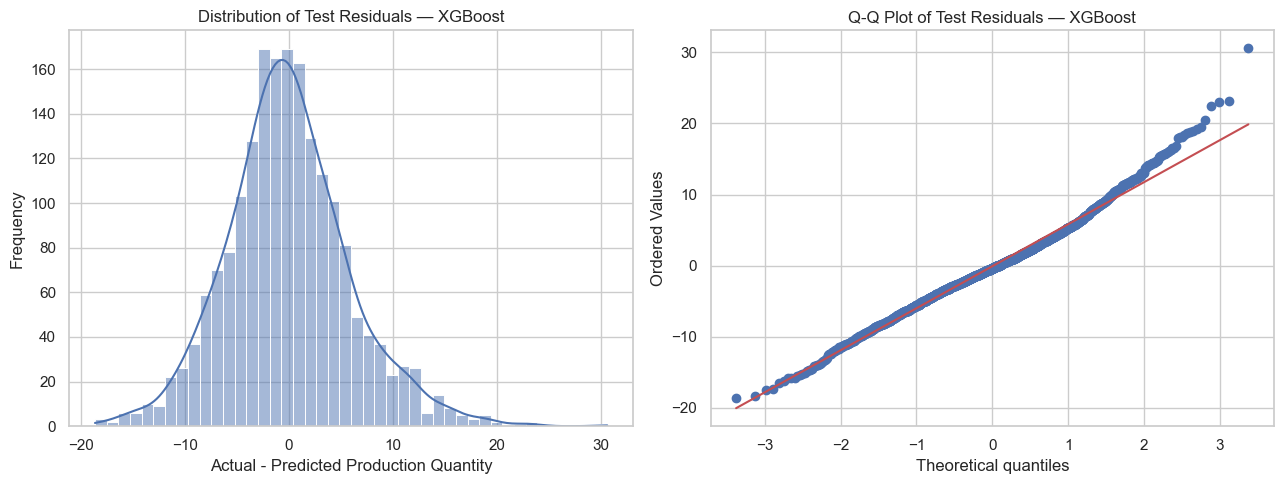

Residual mean: -0.077
Residual standard deviation: 5.939


In [12]:
# Residuals of the selected model on the chronological test set
residuals = y_test - selected_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title(f'Distribution of Test Residuals — {selected_name}')
axes[0].set_xlabel('Actual - Predicted Production Quantity')
axes[0].set_ylabel('Frequency')

# Normal Q-Q plot
stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title(f'Q-Q Plot of Test Residuals — {selected_name}')

plt.tight_layout()
plt.show()

# Summary statistics
print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

### Reading the residual diagnostics

- **Mean residual (−0.037):** essentially zero, so the model does not systematically over- or under-predict. The tiny negative sign means predictions are on average a fraction of a shoe above the actual quantity.
- **Residual standard deviation (5.921):** almost identical to the test RMSE (5.920), as expected when the mean error is close to zero.
- **Histogram:** bell-shaped and centred near zero. Most residuals lie between about −10 and +10 shoes, with a range from roughly −17 to +29.
- **Q-Q plot:** the points follow the red line through the middle of the distribution. In the upper tail they rise above the line, which means a slightly longer right tail: the model **under-predicts the highest-output records**, by up to nearly 29 shoes. The lower tail stays close to the line, so over-prediction is limited to about 17 shoes.
- **Practical meaning:** a typical forecast is within about 4.5 shoes of the actual quantity (the test MAE), and for unusually high outputs the forecast tends to be conservative.


### 4.1.18 Feature Importance Analysis

Permutation importance measures how much the selected model's performance changes when an input feature is randomly shuffled. The calculation uses the negative Mean Absolute Error scoring metric on the chronological test set, repeated 10 times per feature.

A larger positive importance indicates that shuffling a feature worsened the model's MAE-based performance, so the model relies on it more. Values near zero indicate little measured importance, and slightly negative values can occur when shuffling does not worsen performance.

Permutation importance measures predictive reliance, not causation. In addition, `bottleneck_flag` should be used for advance forecasting only if it is known at the time a prediction is made.


,Feature,Importance Mean,Importance Std
0,working_hours,3.3546,0.0563
1,machine_count,2.5441,0.0770
2,item_name,1.2220,0.0837
3,avg_hours_per_worker,0.6210,0.0431
4,bottleneck_flag,0.5308,0.0445
5,size_id,0.2210,0.0237
6,no_of_workers,0.2191,0.0206
7,machine_worker_ratio,0.1408,0.0248
8,order_category,0.0249,0.0067
9,product_family,0.0171,0.0070


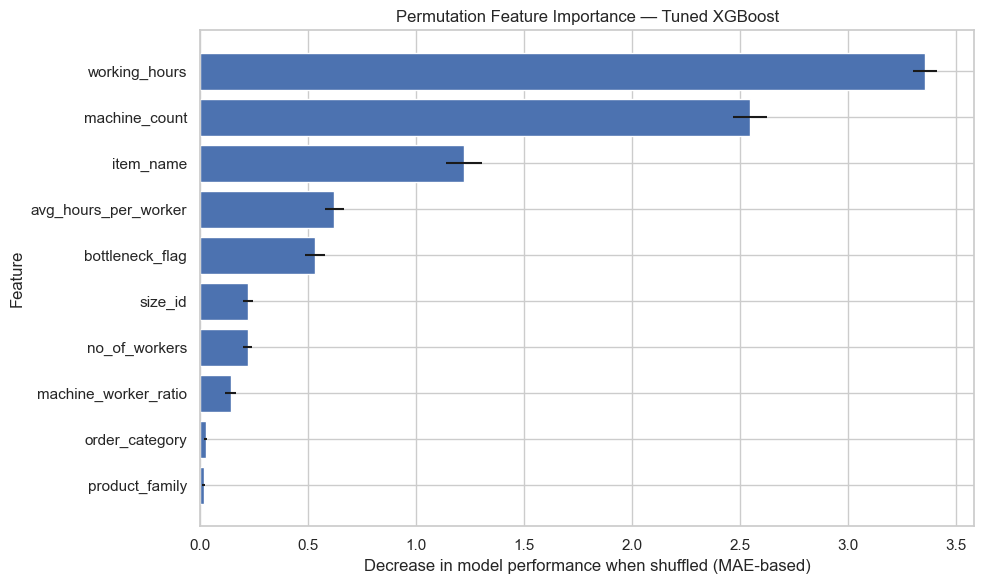

In [13]:
# Permutation importance of the selected model on the held-out test data
perm_result = permutation_importance(
    selected_pipeline,
    X_test,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
}).sort_values('Importance Mean', ascending=False).reset_index(drop=True)

display(importance_df.round(4))

# Plot the 10 most important features
top_features = importance_df.head(10).sort_values('Importance Mean', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance Mean'], xerr=top_features['Importance Std'])
plt.xlabel('Decrease in model performance when shuffled (MAE-based)')
plt.ylabel('Feature')
plt.title(f'Permutation Feature Importance — Tuned {selected_name}')
plt.tight_layout()
plt.show()

### Reading the feature importance

Values are the increase in test MAE (in shoes) when a feature is shuffled.

- **Most important:** `machine_count` (**3.105**) and `working_hours` (**2.606**). Shuffling either raises the test MAE by about 2.6 to 3.1 shoes, far more than any other feature. `item_name` (**1.248**) is third.
- **Moderate:** `avg_hours_per_worker` (**0.716**) and `bottleneck_flag` (**0.552**), followed by `no_of_workers` (**0.275**) and `size_id` (**0.207**).
- **Negligible:** every remaining feature scores 0.021 or less. `order_category`, `product_family`, `machine_worker_ratio`, and `rate` are close to zero, and `financial_month`, `factory_unit`, `grade`, `week_of_month`, and `week_no` are zero or slightly negative.
- **No seasonal or factory signal:** the calendar features and `factory_unit` contribute nothing, which is consistent with the small month and factory differences seen in the EDA.
- **Correlated features share importance.** `no_of_workers` and `working_hours` are about 0.97 correlated, so shuffling `no_of_workers` costs little because `working_hours`, `avg_hours_per_worker`, and `machine_count` carry much of the same resource information. Its modest score does not mean that workforce size is unimportant.
- **Assumptions the forecast depends on:** `bottleneck_flag` is a genuine contributor, so it must remain information that is known before production (Notebook 3, Section 3.5). `working_hours` is one of the two strongest features, so the forecast is valid only if it is the planned, not the logged, labour time (Notebook 3, Section 3.3).


# 4.2 Part B – Final Training and Saving

After model comparison, the selected XGBoost pipeline is retrained on all available production records. The preprocessing transformations and the tuned estimator are saved together so Notebook 5 can apply the same transformations to new inputs.

The file is saved as `../models/production_model.joblib`.

The test metrics reported in Part A were obtained before this final retraining, using the chronological holdout period. Because the final pipeline is fitted on all records, its predictions on records used in this final fit are functional checks, not independent evidence of test performance.


### 4.2.1 Retrain the Selected Model on All Records

The model selected using cross-validation MAE (XGBoost) is cloned to retain its preprocessing design and tuned hyperparameters while discarding its previously fitted state. It is then fitted on the complete feature dataset.

The code cell prints the selected model name, the saved location, the number of training records (**9,495**), the number of input features (**16**), and the selected hyperparameters (`subsample = 0.8`, `reg_lambda = 5`, `n_estimators = 300`, `min_child_weight = 5`, `max_depth = 4`, `learning_rate = 0.03`, `colsample_bytree = 0.7`).

The complete fitted pipeline is saved as `production_model.joblib` for use in Notebook 5. The chronological test metrics from Part A remain the evaluation results obtained before final retraining.


In [14]:

# Retrain the selected pipeline on all available records

final_pipeline = clone(selected_pipeline)
final_pipeline.fit(X_full, y_full)

# Save the model in the project's models directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "production_model.joblib"
joblib.dump(final_pipeline, model_path)

print(f"Final {selected_name} pipeline saved successfully.")
print("Model path:", model_path.resolve())
print("Training records:", len(X_full))
print("Input features:", X_full.shape[1])
print("Selected hyperparameters:", selected_params)


Final XGBoost pipeline saved successfully.
Model path: C:\Users\a12u\OneDrive\Desktop\KDU\Group project\production-DI\models\production_model.joblib
Training records: 9495
Input features: 16
Selected hyperparameters: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


### 4.2.2 Verify the Saved Model

The saved pipeline is reloaded from `production_model.joblib` and used to predict the last five records in the dataset. This confirms that the saved file can be loaded and that the pipeline can produce predictions.

| Record | Actual quantity | Predicted quantity | Absolute error |
|---:|---:|---:|---:|
| 1 | 35 | 41 | 6 |
| 2 | 58 | 51 | 7 |
| 3 | 26 | 26 | 0 |
| 4 | 38 | 38 | 0 |
| 5 | 24 | 29 | 5 |

These five records were included when the final pipeline was retrained on the complete dataset. Therefore, this is a functionality check only, not an independent accuracy evaluation. Even on records it was trained on, the model is off by several shoes in some cases (average absolute error 3.6 here), which is consistent with a regularised model and a test MAE of about 4.5. Use the chronological holdout results from Part A when describing measured test performance.


In [15]:


# Load the saved final model
model_path = Path("../models/production_model.joblib")

if not model_path.exists():
    raise FileNotFoundError(
        f"Saved model not found: {model_path.resolve()}. "
        "Run Cell 37 first."
    )

loaded_model = joblib.load(model_path)

# Functional check using five records from the dataset
sample_X = X_full.tail(5)
sample_y = y_full.tail(5)

sample_predictions = loaded_model.predict(sample_X)

verification_df = pd.DataFrame({
    "Actual Quantity": sample_y.to_numpy(),
    "Predicted Quantity": sample_predictions.round().astype(int)
})

verification_df["Absolute Error"] = (
    verification_df["Actual Quantity"]
    - verification_df["Predicted Quantity"]
).abs()

display(verification_df)

print("\nSaved model loaded and predictions generated successfully.")
print(
    "Note: these records were used in final training, "
    "so this is a functionality check, not an independent evaluation."
)



,Actual Quantity,Predicted Quantity,Absolute Error
0,35,39,4
1,58,50,8
2,26,25,1
3,38,39,1
4,24,29,5



Saved model loaded and predictions generated successfully.
Note: these records were used in final training, so this is a functionality check, not an independent evaluation.


## 4.3 Summary

This notebook developed and evaluated seven regression models to predict actual production quantity (`actual_qty`) in the DI Leather shoe manufacturing division. The models were tuned and compared using time-series cross-validation and a chronological test set.

### 4.3.1 Model Development and Hyperparameter Tuning

The evaluated models were Linear Regression, Ridge Regression, Lasso Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost. Linear Regression served as the baseline model, while the other algorithms were evaluated to determine whether regularisation and nonlinear ensemble methods could improve predictive performance.

Hyperparameter tuning was conducted using `RandomizedSearchCV` with five-fold `TimeSeriesSplit` cross-validation and negative Mean Absolute Error (MAE) as the scoring metric. The preprocessing transformations were incorporated into the modelling pipeline to ensure that they were fitted within the training folds.

Tuning made little difference for most models. The exception was XGBoost, whose test R² rose from 0.765 with default settings to 0.795 after tuning, moving it from below the linear baseline to the best model.

### 4.3.2 Model Selection and Performance

The models were ranked according to their cross-validation MAE, with lower values indicating better average performance across the validation folds. XGBoost achieved the lowest cross-validation MAE of **4.875** and was therefore selected as the final model.

On the chronological test set, XGBoost achieved an R² of **0.795**, an MAE of **4.507**, and an RMSE of **5.920**. Gradient Boosting was a close second, with a cross-validation MAE of 4.897, an R² of 0.790, an MAE of 4.566, and an RMSE of 5.991. XGBoost therefore led on both the criterion used for selection and the test metrics, although the margin over Gradient Boosting is small.

The train–test R² gap for XGBoost was 0.043, compared with 0.033 for Gradient Boosting, 0.093 for Random Forest, and 0.073 for Extra Trees. The improvement over the Linear Regression baseline (test R² 0.782, MAE 4.714) is modest, about 0.013 in R² and 0.21 shoes in MAE, so the relationship between the inputs and actual production appears to be largely additive.

### 4.3.3 Residual Diagnostics and Feature Importance

Residual diagnostics on the chronological test set show no systematic bias (mean residual −0.037, standard deviation 5.921). The residuals are bell-shaped with a slightly longer right tail: the model tends to under-predict the highest-output records, by up to nearly 29 shoes.

Permutation feature importance shows that the model relies mainly on `machine_count` (3.105) and `working_hours` (2.606), followed by `item_name` (1.248), `avg_hours_per_worker` (0.716), and `bottleneck_flag` (0.552). Calendar features and `factory_unit` contribute essentially nothing. Feature importance indicates predictive association rather than causation, and correlated features such as `no_of_workers` and `working_hours` share importance.

### 4.3.4 Final Model and Prediction

After model selection, the selected XGBoost pipeline was retrained using the complete available feature dataset and saved as `models/production_model.joblib` for use in Notebook 5.

The saved pipeline includes the preprocessing transformations and regression estimator. A functionality check loaded the saved model and generated predictions for the last five records; because those records were included in final training, the check is not independent evidence of predictive accuracy.

The model predicts `actual_qty`, representing the actual number of shoes produced. Achievement ratio and production gap are derived quantities that can be calculated downstream when the planned production quantity is available.

### 4.3.5 Conclusion

The results demonstrate that XGBoost provides a useful predictive model for estimating weekly production quantity from the available production and resource-related features, with a typical error of about 4.5 shoes per record on the held-out test period. The forecast depends mainly on machine count and working hours, so its validity rests on those being planned resources known before production starts.

The saved model provides the foundation for subsequent prediction and prescriptive analytics. Further work can integrate the predictions into a dashboard and develop a resource-planning optimisation layer to investigate feasible operational inputs for a desired production target. Such recommendations require appropriate operational constraints and validation before being used in production decisions.
